In [94]:
#wether a particular customer will stay with us or choose a different provider

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels as st
import sklearn as sk

In [96]:
churn_data = pd.read_csv("/content/churn_data.csv")

In [97]:
customer_data = pd.read_csv("/content/customer_data.csv")

In [98]:
internet_data = pd.read_csv("/content/internet_data.csv")

In [99]:
churn_data.shape


(7043, 9)

In [100]:
customer_data.shape

(7043, 5)

In [101]:
internet_data.shape

(7043, 9)

In [102]:
churn_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [103]:
customer_data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [104]:
internet_data.head()

,customerID,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,No,Fiber optic,No,No,No,No,No,No


In [105]:
churn_data.info()
customer_data.info()
internet_data.info()
#TotalCharges is wrong as it is object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   object 
 3   Contract          7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
 8   Churn             7043 non-null   object 
dtypes: float64(1), int64(1), object(7)
memory usage: 495.3+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null  

In [106]:
#combining all data files into a single data frame
# Will be using pd.merge
# There is also pd.concat

In [107]:
df1 = pd.merge(churn_data,customer_data,how = "inner",on = "customerID")

In [108]:
telecom_data = pd.merge(df1,internet_data,how = "inner",on = "customerID")

In [109]:
telecom_data.shape

(7043, 21)

In [110]:
telecom_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,...,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Female,...,Yes,No,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No,Male,...,No,No,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Male,...,No,No,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Male,...,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Female,...,No,No,No,Fiber optic,No,No,No,No,No,No


In [111]:
telecom_data.shape

(7043, 21)

In [112]:
telecom_data.describe()

,tenure,MonthlyCharges,SeniorCitizen
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,0.162147
std,24.559481,30.090047,0.368612
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,0.000000
50%,29.000000,70.350000,0.000000
75%,55.000000,89.850000,0.000000
max,72.000000,118.750000,1.000000


In [113]:
telecom_data.info()
# 7   TotalCharges      7043 non-null   object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   object 
 3   Contract          7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
 8   Churn             7043 non-null   object 
 9   gender            7043 non-null   object 
 10  SeniorCitizen     7043 non-null   int64  
 11  Partner           7043 non-null   object 
 12  Dependents        7043 non-null   object 
 13  MultipleLines     7043 non-null   object 
 14  InternetService   7043 non-null   object 
 15  OnlineSecurity    7043 non-null   object 
 16  OnlineBackup      7043 non-null   object 


In [114]:
telecom_data['TotalCharges'] = pd.to_numeric(telecom_data['TotalCharges'], errors='coerce')
telecom_data['TotalCharges'].dtype

dtype('float64')

In [115]:
telecom_data['MultipleLines'].value_counts()
#anywhere where there are more than two values it will go into getdummies
#if less then we use map()

,count
MultipleLines,
No,3390
Yes,2971
No phone service,682


In [116]:
#using map function on the columns which have Yes/No to 0 and 1

In [117]:
# Recreate telecom_data since the columns were already overwritten with NaN
df1 = pd.merge(churn_data, customer_data, how="inner", on="customerID")
telecom_data = pd.merge(df1, internet_data, how="inner", on="customerID")
telecom_data['TotalCharges'] = pd.to_numeric(telecom_data['TotalCharges'], errors='coerce')

varlist = ['PhoneService', 'PaperlessBilling', 'Partner', 'Dependents', 'Churn']

def binary_map(x):
    return x.map({'Yes': 1, 'No': 0})

telecom_data[varlist] = telecom_data[varlist].apply(binary_map)

In [118]:
telecom_data.shape

(7043, 21)

In [119]:
telecom_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,...,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,1,0,Month-to-month,1,Electronic check,29.85,29.85,0,Female,...,1,0,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,34,1,One year,0,Mailed check,56.95,1889.50,0,Male,...,0,0,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,2,1,Month-to-month,1,Mailed check,53.85,108.15,1,Male,...,0,0,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,45,0,One year,0,Bank transfer (automatic),42.30,1840.75,0,Male,...,0,0,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,2,1,Month-to-month,1,Electronic check,70.70,151.65,1,Female,...,0,0,No,Fiber optic,No,No,No,No,No,No


In [120]:
telecom_data['OnlineSecurity'].value_counts()

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


In [121]:
telecom_data[['Contract', 'PaymentMethod','gender','InternetService']].value_counts()

Contract        PaymentMethod     gender  InternetService
Month-to-month  Electronic check  Male    Fiber optic        661
                                  Female  Fiber optic        646
                                          DSL                250
                                  Male    DSL                224
                Mailed check      Male    DSL                199
                                                            ... 
One year        Mailed check      Male    Fiber optic         12
Two year        Mailed check      Female  Fiber optic         12
                Electronic check  Female  No                  10
                Mailed check      Male    Fiber optic          9
                Electronic check  Male    No                   8
Name: count, Length: 72, dtype: int64

In [122]:
telecom_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   int64  
 3   Contract          7043 non-null   object 
 4   PaperlessBilling  7043 non-null   int64  
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7032 non-null   float64
 8   Churn             7043 non-null   int64  
 9   gender            7043 non-null   object 
 10  SeniorCitizen     7043 non-null   int64  
 11  Partner           7043 non-null   int64  
 12  Dependents        7043 non-null   int64  
 13  MultipleLines     7043 non-null   object 
 14  InternetService   7043 non-null   object 
 15  OnlineSecurity    7043 non-null   object 
 16  OnlineBackup      7043 non-null   object 


In [123]:
#get dummies across multiple values in features
status = pd.get_dummies(telecom_data[['Contract', 'PaymentMethod','gender','InternetService']],drop_first = True)

In [124]:
status.shape

(7043, 8)

In [125]:
telecom_data

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,...,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,1,0,Month-to-month,1,Electronic check,29.85,29.85,0,Female,...,1,0,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,34,1,One year,0,Mailed check,56.95,1889.50,0,Male,...,0,0,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,2,1,Month-to-month,1,Mailed check,53.85,108.15,1,Male,...,0,0,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,45,0,One year,0,Bank transfer (automatic),42.30,1840.75,0,Male,...,0,0,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,2,1,Month-to-month,1,Electronic check,70.70,151.65,1,Female,...,0,0,No,Fiber optic,No,No,No,No,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,24,1,One year,1,Mailed check,84.80,1990.50,0,Male,...,1,1,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes
7039,2234-XADUH,72,1,One year,1,Credit card (automatic),103.20,7362.90,0,Female,...,1,1,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes
7040,4801-JZAZL,11,0,Month-to-month,1,Electronic check,29.60,346.45,0,Female,...,1,1,No phone service,DSL,Yes,No,No,No,No,No
7041,8361-LTMKD,4,1,Month-to-month,1,Mailed check,74.40,306.60,1,Male,...,1,0,Yes,Fiber optic,No,No,No,No,No,No


In [126]:
telecom_data = pd.concat([telecom_data,status],axis = 1)
telecom_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,...,StreamingTV,StreamingMovies,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,gender_Male,InternetService_Fiber optic,InternetService_No
0,7590-VHVEG,1,0,Month-to-month,1,Electronic check,29.85,29.85,0,Female,...,No,No,False,False,False,True,False,False,False,False
1,5575-GNVDE,34,1,One year,0,Mailed check,56.95,1889.50,0,Male,...,No,No,True,False,False,False,True,True,False,False
2,3668-QPYBK,2,1,Month-to-month,1,Mailed check,53.85,108.15,1,Male,...,No,No,False,False,False,False,True,True,False,False
3,7795-CFOCW,45,0,One year,0,Bank transfer (automatic),42.30,1840.75,0,Male,...,No,No,True,False,False,False,False,True,False,False
4,9237-HQITU,2,1,Month-to-month,1,Electronic check,70.70,151.65,1,Female,...,No,No,False,False,False,True,False,False,True,False


In [127]:
status.head()

,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,gender_Male,InternetService_Fiber optic,InternetService_No
0,False,False,False,True,False,False,False,False
1,True,False,False,False,True,True,False,False
2,False,False,False,False,True,True,False,False
3,True,False,False,False,False,True,False,False
4,False,False,False,True,False,False,True,False


In [128]:
status.shape

(7043, 8)

In [129]:
telecom_data.shape

(7043, 29)

In [130]:
telecom_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 29 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   customerID                             7043 non-null   object 
 1   tenure                                 7043 non-null   int64  
 2   PhoneService                           7043 non-null   int64  
 3   Contract                               7043 non-null   object 
 4   PaperlessBilling                       7043 non-null   int64  
 5   PaymentMethod                          7043 non-null   object 
 6   MonthlyCharges                         7043 non-null   float64
 7   TotalCharges                           7032 non-null   float64
 8   Churn                                  7043 non-null   int64  
 9   gender                                 7043 non-null   object 
 10  SeniorCitizen                          7043 non-null   int64  
 11  Part

In [131]:
telecom_data.columns

Index(['customerID', 'tenure', 'PhoneService', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender',
       'SeniorCitizen', 'Partner', 'Dependents', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'gender_Male', 'InternetService_Fiber optic', 'InternetService_No'],
      dtype='object')

In [132]:
telecom_data = telecom_data.drop(['Contract', 'PaymentMethod','gender','InternetService'],axis = 1)

In [133]:
telecom_data.shape

(7043, 25)

In [134]:
telecom_data['MultipleLines'].value_counts()

,count
MultipleLines,
No,3390
Yes,2971
No phone service,682


In [135]:
telecom_data['PhoneService'].value_counts()

,count
PhoneService,
1,6361
0,682


In [136]:
# Creating dummy variables for the remaining categorical variables and dropping the levels with big names

# Creating the dummy variable for the variables 'MultipleLines'
ml = pd.get_dummies(telecom_data['MultipleLines'], prefix = 'MultipleLines')
ml = ml.drop(['MultipleLines_No phone service'], axis = 1)
telecom_data = pd.concat([telecom_data, ml], axis = 1)

In [137]:
telecom_data.shape

(7043, 27)

In [138]:
# Creating the dummy variables for the variable 'Online Security'
os = pd.get_dummies(telecom_data['OnlineSecurity'], prefix = 'OnlineSecurity')
os = os.drop(['OnlineSecurity_No internet service'], axis = 1)
telecom_data = pd.concat([telecom_data, os], axis = 1)

In [139]:
telecom_data['OnlineSecurity'].value_counts()

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


In [140]:
telecom_data.shape

(7043, 29)

In [141]:
# Creating the dummy variables for the variable 'Online Backup'
ob = pd.get_dummies(telecom_data['OnlineBackup'], prefix = 'OnlineBackup')
ob = ob.drop(['OnlineBackup_No internet service'], axis = 1)
telecom_data = pd.concat([telecom_data, ob], axis = 1)

In [142]:
telecom_data.shape

(7043, 31)

In [143]:
# Creating the dummy variables for the variable 'Device Protection'
dp = pd.get_dummies(telecom_data['DeviceProtection'], prefix = 'DeviceProtection')
dp = dp.drop(['DeviceProtection_No internet service'], axis = 1)
telecom_data = pd.concat([telecom_data, dp], axis = 1)

In [144]:
telecom_data.shape

(7043, 33)

In [145]:
# Creating the dummy variables for the variable 'tech Support'
ts = pd.get_dummies(telecom_data['TechSupport'], prefix = 'TechSupport')
ts = ts.drop(['TechSupport_No internet service'], axis = 1)
telecom_data = pd.concat([telecom_data, ts], axis = 1)

In [146]:
telecom_data.shape

(7043, 35)

In [147]:

# Creating the dummy variables for the variable 'Streaming TV'
st = pd.get_dummies(telecom_data['StreamingTV'], prefix = 'StreamingTV')
st = st.drop(['StreamingTV_No internet service'], axis = 1)
telecom_data = pd.concat([telecom_data, st], axis = 1)

In [148]:
telecom_data.shape

(7043, 37)

In [149]:
# Creating the dummy variables for the variable 'Streaming Movies'
sm = pd.get_dummies(telecom_data['StreamingMovies'], prefix = 'StreamingMovies')
sm = sm.drop(['StreamingMovies_No internet service'], axis = 1)
telecom_data = pd.concat([telecom_data, sm], axis = 1)

In [150]:
telecom_data.shape

(7043, 39)

In [151]:
telecom = telecom_data.drop(['MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies'], axis=1)
telecom.head()

,customerID,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,SeniorCitizen,Partner,Dependents,...,OnlineBackup_No,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_Yes,TechSupport_No,TechSupport_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes
0,7590-VHVEG,1,0,1,29.85,29.85,0,0,1,0,...,False,True,True,False,True,False,True,False,True,False
1,5575-GNVDE,34,1,0,56.95,1889.50,0,0,0,0,...,True,False,False,True,True,False,True,False,True,False
2,3668-QPYBK,2,1,1,53.85,108.15,1,0,0,0,...,False,True,True,False,True,False,True,False,True,False
3,7795-CFOCW,45,0,0,42.30,1840.75,0,0,0,0,...,True,False,False,True,False,True,True,False,True,False
4,9237-HQITU,2,1,1,70.70,151.65,1,0,0,0,...,True,False,True,False,True,False,True,False,True,False


In [152]:
telecom.shape

(7043, 32)

In [153]:
telecom.describe()

,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,SeniorCitizen,Partner,Dependents
count,7043.000000,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,0.903166,0.592219,64.761692,2283.300441,0.265370,0.162147,0.483033,0.299588
std,24.559481,0.295752,0.491457,30.090047,2266.771362,0.441561,0.368612,0.499748,0.458110
min,0.000000,0.000000,0.000000,18.250000,18.800000,0.000000,0.000000,0.000000,0.000000
25%,9.000000,1.000000,0.000000,35.500000,401.450000,0.000000,0.000000,0.000000,0.000000
50%,29.000000,1.000000,1.000000,70.350000,1397.475000,0.000000,0.000000,0.000000,0.000000
75%,55.000000,1.000000,1.000000,89.850000,3794.737500,1.000000,0.000000,1.000000,1.000000
max,72.000000,1.000000,1.000000,118.750000,8684.800000,1.000000,1.000000,1.000000,1.000000


In [154]:
telecom.isnull().sum()

,0
customerID,0
tenure,0
PhoneService,0
PaperlessBilling,0
MonthlyCharges,0
TotalCharges,11
Churn,0
SeniorCitizen,0
Partner,0
Dependents,0


In [155]:
#now we drop TotalCharges null values
# telecom['TotalCharges'].dropna()
#OR
telecom = telecom[~pd.isna(telecom['TotalCharges'])]

In [156]:
telecom.shape

(7032, 32)

cleaning done

In [157]:
#check for outliers
num_telecom = telecom[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']]

In [158]:
num_telecom.describe(percentiles = [0.25,0.5,0.75,.90,.95,.99])

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441,0.162400
std,24.545260,30.085974,2266.771362,0.368844
min,1.000000,18.250000,18.800000,0.000000
25%,9.000000,35.587500,401.450000,0.000000
50%,29.000000,70.350000,1397.475000,0.000000
75%,55.000000,89.862500,3794.737500,0.000000
90%,69.000000,102.645000,5976.640000,1.000000
95%,72.000000,107.422500,6923.590000,1.000000
99%,72.000000,114.734500,8039.883000,1.000000


In [159]:
import plotly.express as px
px.box(telecom, y='tenure')

In [160]:
import plotly.express as px
px.box(telecom, y='MonthlyCharges')

In [161]:
px.scatter(telecom, x='SeniorCitizen', y='MonthlyCharges')

In [162]:
#sns.scatterplot(telecom, y='MonthlyCharges', x='customerID',hue = 'SeniorCitizen')

In [163]:
telecom.shape

(7032, 32)

In [164]:
telecom.columns

Index(['customerID', 'tenure', 'PhoneService', 'PaperlessBilling',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'SeniorCitizen', 'Partner',
       'Dependents', 'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'gender_Male', 'InternetService_Fiber optic', 'InternetService_No',
       'MultipleLines_No', 'MultipleLines_Yes', 'OnlineSecurity_No',
       'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_Yes',
       'DeviceProtection_No', 'DeviceProtection_Yes', 'TechSupport_No',
       'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_Yes'],
      dtype='object')

Whenever a categorical problem is taken into consideration no feature having unique values or primary key can be taken into feature set. i.e why are dropping customerID

In [165]:
X = telecom.drop(['customerID','Churn'],axis = 1)
y = telecom['Churn']

# Step 4: Train Test Split

In [166]:
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

In [167]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3, random_state = 100)

In [168]:
#Feature Scaling
from sklearn.preprocessing import StandardScaler

In [169]:
scaler = StandardScaler()
X_train[['tenure', 'MonthlyCharges', 'TotalCharges']] = scaler.fit_transform(X_train[['tenure', 'MonthlyCharges', 'TotalCharges']])

In [170]:
X_train.head()

,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,Contract_One year,Contract_Two year,...,OnlineBackup_No,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_Yes,TechSupport_No,TechSupport_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes
879,0.019693,1,1,-0.338074,-0.276449,0,0,0,False,False,...,False,True,True,False,True,False,True,False,True,False
5790,0.305384,0,1,-0.464443,-0.112702,0,1,1,False,False,...,False,True,True,False,True,False,False,True,False,True
6498,-1.286319,1,1,0.581425,-0.974430,0,0,0,False,False,...,False,True,False,True,True,False,True,False,True,False
880,-0.919003,1,1,1.505913,-0.550676,0,0,0,False,False,...,False,True,False,True,False,True,False,True,False,True
2784,-1.163880,1,1,1.106854,-0.835971,0,0,1,False,False,...,True,False,False,True,False,True,False,True,False,True


In [171]:
#Check the churn rate for the output column
churn = sum(telecom['Churn'])/len(telecom['Churn'])

In [172]:
churn*100

26.578498293515356

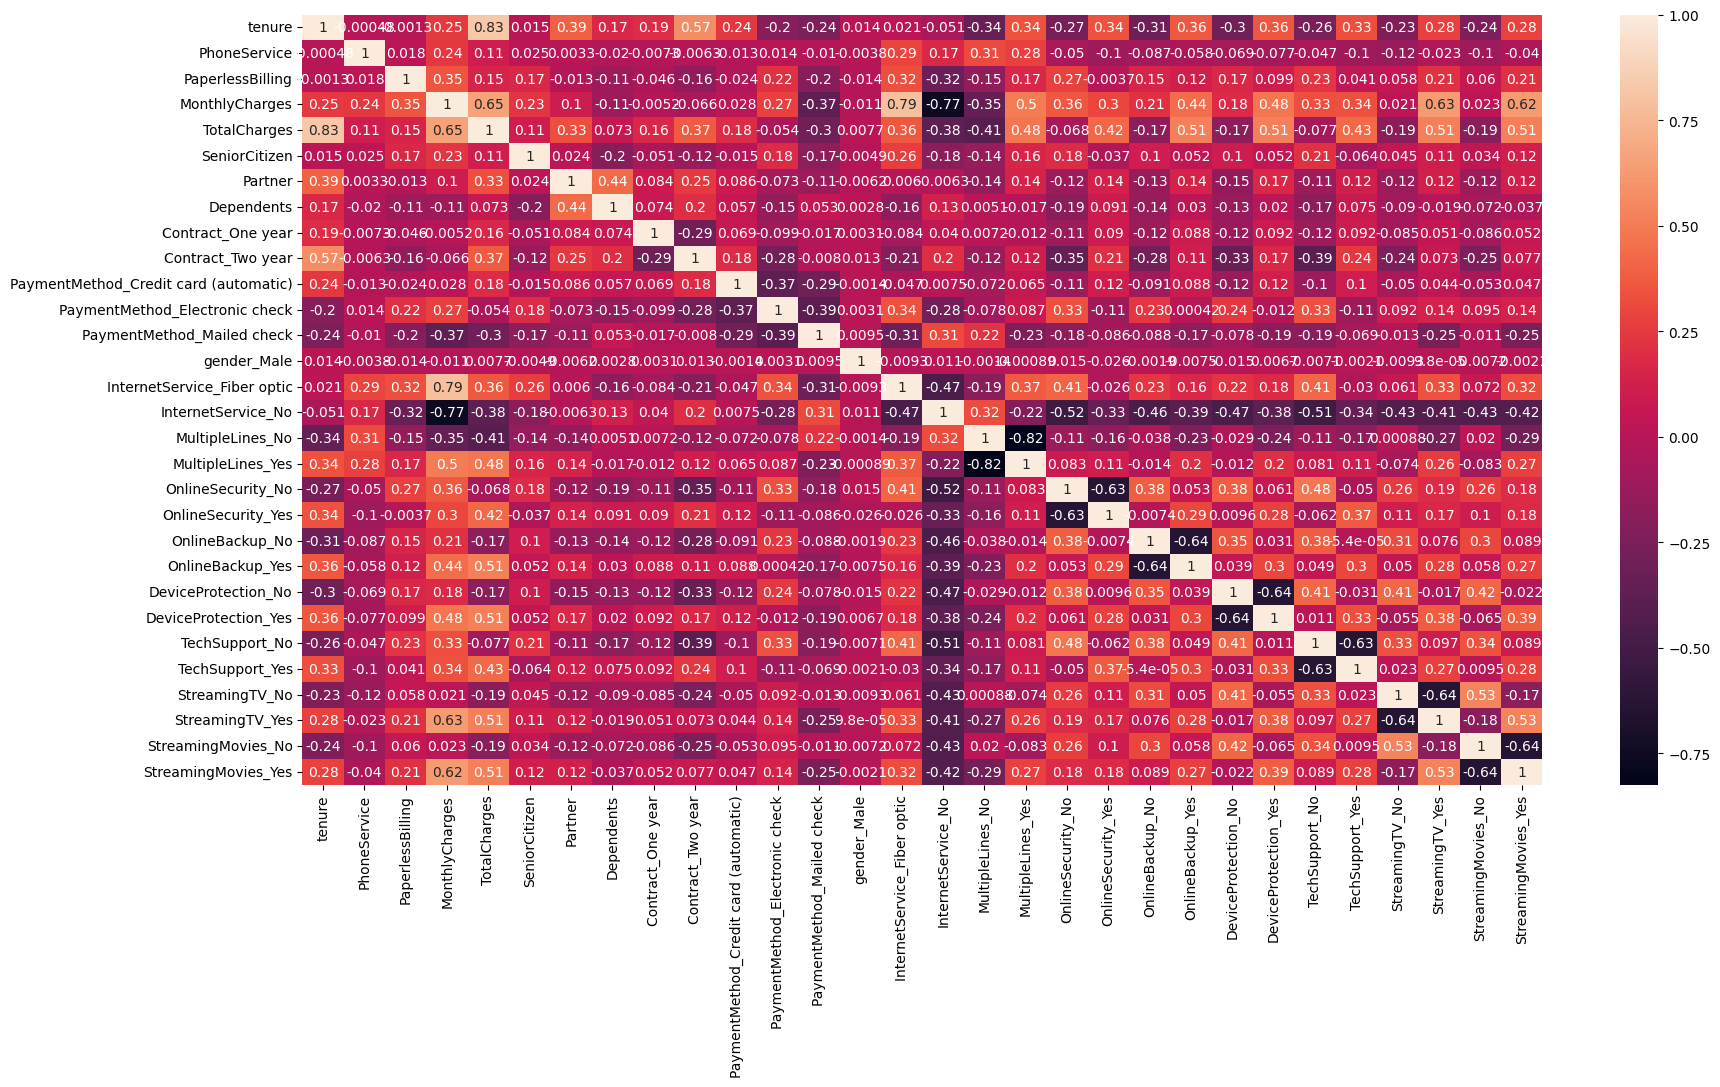

In [173]:
#Feature Engineering make a heatmap across all the features
#Very Important
plt.figure(figsize=(20,10))
sns.heatmap(X_train.corr(),annot = True)
plt.show()


In [174]:
X_test = X_test.drop(
    ['MultipleLines_No','OnlineSecurity_No','OnlineBackup_No','DeviceProtection_No','TechSupport_No','StreamingTV_No','StreamingMovies_No'],axis=1)

In [175]:
X_train = X_train.drop(
    ['MultipleLines_No','OnlineSecurity_No','OnlineBackup_No','DeviceProtection_No','TechSupport_No','StreamingTV_No','StreamingMovies_No'],axis=1)

Step 7: Model Building

In [176]:
import statsmodels.api as sm

In [177]:
from numpy.random import binomial
m1 = sm.GLM(y_train,(sm.add_constant(X_train)),family = sm.families.Binomial())
m1.fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                  Churn   No. Observations:                 4922
Model:                            GLM   Df Residuals:                     4898
Model Family:                Binomial   Df Model:                           23
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2004.7
Date:                Tue, 27 Oct 2026   Deviance:                       4009.4
Time:                        06:12:40   Pearson chi2:                 6.07e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2844
Covariance Type:            nonrobust                                         
=========================================================================================================
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -3.9382      1.546     -2.547      0.011      -6.969      -0.908
tenure                                   -1.5172      0.189     -8.015      0.000      -1.888      -1.146
PhoneService                              0.9507      0.789      1.205      0.228      -0.595       2.497
PaperlessBilling                          0.3254      0.090      3.614      0.000       0.149       0.502
MonthlyCharges                           -2.1806      1.160     -1.880      0.060      -4.454       0.092
TotalCharges                              0.7332      0.198      3.705      0.000       0.345       1.121
SeniorCitizen                             0.3984      0.102      3.924      0.000       0.199       0.597
Partner                                   0.0374      0.094      0.399      0.690      -0.146       0.221
Dependents                               -0.1430      0.107     -1.332      0.183      -0.353       0.067
Contract_One year                        -0.6578      0.129     -5.106      0.000      -0.910      -0.405
Contract_Two year                        -1.2455      0.212     -5.874      0.000      -1.661      -0.830
PaymentMethod_Credit card (automatic)    -0.2577      0.137     -1.883      0.060      -0.526       0.011
PaymentMethod_Electronic check            0.1615      0.113      1.434      0.152      -0.059       0.382
PaymentMethod_Mailed check               -0.2536      0.137     -1.845      0.065      -0.523       0.016
gender_Male                              -0.0346      0.078     -0.442      0.658      -0.188       0.119
InternetService_Fiber optic               2.5124      0.967      2.599      0.009       0.618       4.407
InternetService_No                       -2.7792      0.982     -2.831      0.005      -4.703      -0.855
MultipleLines_Yes                         0.5623      0.214      2.628      0.009       0.143       0.982
OnlineSecurity_Yes                       -0.0245      0.216     -0.113      0.910      -0.448       0.399
OnlineBackup_Yes                          0.1740      0.212      0.822      0.411      -0.241       0.589
DeviceProtection_Yes                      0.3229      0.215      1.501      0.133      -0.099       0.744
TechSupport_Yes                          -0.0305      0.216     -0.141      0.888      -0.455       0.394
StreamingTV_Yes                           0.9598      0.396      2.423      0.015       0.183       1.736
StreamingMovies_Yes                       0.8484      0.396      2.143      0.032       0.072       1.624
=========================================================================================================
"""

In [178]:
#dropping all with high P values
X_test = X_test.drop(
    ['PhoneService','Partner','Dependents','gender_Male','DeviceProtection_Yes','OnlineBackup_Yes','TechSupport_Yes','PaymentMethod_Electronic check'],axis=1)

In [179]:
X_train = X_train.drop(
    ['PhoneService','Partner','Dependents','gender_Male','DeviceProtection_Yes','OnlineBackup_Yes','TechSupport_Yes','PaymentMethod_Electronic check'],axis=1)

In [180]:
X_test = X_test.drop(['OnlineSecurity_Yes'],axis=1)

In [181]:
X_train = X_train.drop(['OnlineSecurity_Yes'],axis=1)

In [183]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression() #model 1

In [184]:
#Redundant Feature Elimination
#a automatic feature selection
#model, how many features do you want in a

In [185]:
from sklearn.feature_selection import RFE
rfe = RFE(estimator=logreg, n_features_to_select=10)
rfe = rfe.fit(X_train,y_train)

In [186]:
rfe.support_ #gives a true false list of all the columns that are kept or removed, true are the ones kept and false are the ones removed.

array([ True, False,  True,  True,  True,  True,  True, False, False,
        True,  True, False,  True,  True])

In [188]:
col = X_train.columns[rfe.support_]
col

Index(['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen',
       'Contract_One year', 'Contract_Two year', 'InternetService_Fiber optic',
       'InternetService_No', 'StreamingTV_Yes', 'StreamingMovies_Yes'],
      dtype='object')

In [187]:
X_train.columns

Index(['tenure', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'SeniorCitizen', 'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check',
       'InternetService_Fiber optic', 'InternetService_No',
       'MultipleLines_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes'],
      dtype='object')

In [189]:
list(zip(X_train.columns,rfe.support_,rfe.ranking_))
# rfe ranking states all 1 are the kept features and removes are ranked from the least upwards

[('tenure', np.True_, np.int64(1)),
 ('PaperlessBilling', np.False_, np.int64(5)),
 ('MonthlyCharges', np.True_, np.int64(1)),
 ('TotalCharges', np.True_, np.int64(1)),
 ('SeniorCitizen', np.True_, np.int64(1)),
 ('Contract_One year', np.True_, np.int64(1)),
 ('Contract_Two year', np.True_, np.int64(1)),
 ('PaymentMethod_Credit card (automatic)', np.False_, np.int64(4)),
 ('PaymentMethod_Mailed check', np.False_, np.int64(3)),
 ('InternetService_Fiber optic', np.True_, np.int64(1)),
 ('InternetService_No', np.True_, np.int64(1)),
 ('MultipleLines_Yes', np.False_, np.int64(2)),
 ('StreamingTV_Yes', np.True_, np.int64(1)),
 ('StreamingMovies_Yes', np.True_, np.int64(1))]

In [190]:
X_train.columns

Index(['tenure', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'SeniorCitizen', 'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check',
       'InternetService_Fiber optic', 'InternetService_No',
       'MultipleLines_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes'],
      dtype='object')

In [191]:
X_train.columns[~rfe.suppport_]

AttributeError: 'RFE' object has no attribute 'suppport_'

In [192]:
#assesing the model with stats model again
X_train_sm = sm.add_constant(X_train[col])
logm2 = sm.GLM(y_train,X_train_sm, family = sm.families.Binomial())  #model 2
res = logm2.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                  Churn   No. Observations:                 4922
Model:                            GLM   Df Residuals:                     4911
Model Family:                Binomial   Df Model:                           10
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2041.2
Date:                Tue, 27 Oct 2026   Deviance:                       4082.5
Time:                        06:37:08   Pearson chi2:                 6.22e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2737
Covariance Type:            nonrobust                                         
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -2.1157      0.139    -15.224      0.000      -2.388      -1.843
tenure                         -1.4312      0.183     -7.817      0.000      -1.790      -1.072
MonthlyCharges                 -0.8497      0.170     -5.001      0.000      -1.183      -0.517
TotalCharges                    0.6719      0.195      3.451      0.001       0.290       1.053
SeniorCitizen                   0.5246      0.098      5.358      0.000       0.333       0.717
Contract_One year              -0.8254      0.126     -6.568      0.000      -1.072      -0.579
Contract_Two year              -1.5354      0.207     -7.421      0.000      -1.941      -1.130
InternetService_Fiber optic     1.7387      0.190      9.134      0.000       1.366       2.112
InternetService_No             -1.6731      0.204     -8.205      0.000      -2.073      -1.273
StreamingTV_Yes                 0.5846      0.109      5.386      0.000       0.372       0.797
StreamingMovies_Yes             0.4719      0.107      4.427      0.000       0.263       0.681
===============================================================================================
"""

In [193]:
y_train_pred = res.predict(X_train_sm.astype(float))
y_train_pred #whether the person will churn by how much probablity

,0
879,0.114824
5790,0.235517
6498,0.578150
880,0.585423
2784,0.699087
...,...
79,0.010330
3934,0.184088
5964,0.058691
6947,0.128340


In [194]:
y_train_pred = y_train_pred.values.reshape(-1)
y_train_pred[:10]

array([0.11482365, 0.23551671, 0.57814993, 0.58542298, 0.69908704,
       0.33055784, 0.46896244, 0.7317239 , 0.16706547, 0.50138234])

In [197]:
y_train_pred_final = pd.DataFrame({'Churn':y_train.values, 'Churn_Prob':y_train_pred})
y_train_pred_final['CustID'] = y_train.index
y_train_pred_final.head()
#this shows the probablity of churning and whether the person in actually churning or not

,Churn,Churn_Prob,CustID
0,0,0.114824,879
1,0,0.235517,5790
2,1,0.578150,6498
3,1,0.585423,880
4,1,0.699087,2784


# Running model at 0.5

In [ ]:
#mapping the churn probablity with 0 and 1

In [198]:
y_train_pred_final['final_predicted'] = y_train_pred_final.Churn_Prob.map(lambda x: 1 if x > 0.5 else 0)
y_train_pred_final.head()

,Churn,Churn_Prob,CustID,final_predicted
0,0,0.114824,879,0
1,0,0.235517,5790,0
2,1,0.578150,6498,1
3,1,0.585423,880,1
4,1,0.699087,2784,1


In [199]:
from sklearn import metrics
confusion = metrics.confusion_matrix(y_train_pred_final.Churn, y_train_pred_final.final_predicted )
print(confusion)

[[3263  372]
 [ 594  693]]


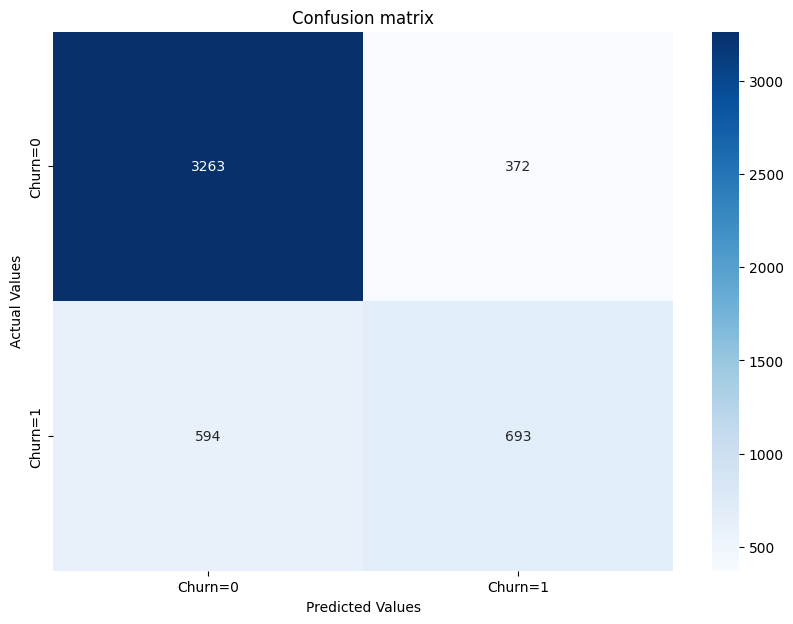

In [203]:
#visualizing the confusion metrics
plt.figure(figsize = (10,7))
sns.heatmap(confusion, annot=True, fmt='d', cmap="Blues", xticklabels=['Churn=0', 'Churn=1'], yticklabels=['Churn=0', 'Churn=1'])
plt.title("Confusion matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()
#0 = non churn
#1 = churn
#3956/(3263+693+594+372)

In [206]:
print(metrics.accuracy_score(y_train_pred_final.Churn, y_train_pred_final.final_predicted))

0.8037383177570093


In [204]:
print(metrics.classification_report(y_train_pred_final.Churn, y_train_pred_final.final_predicted ))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      3635
           1       0.65      0.54      0.59      1287

    accuracy                           0.80      4922
   macro avg       0.75      0.72      0.73      4922
weighted avg       0.79      0.80      0.80      4922



In [ ]:
#Precision is Tp/Tp+Fp
#i.e when we say "this person will churn" we are right 65% of the time


#Recall(Sensitivity) Tp/(Tp+Fn)
#i.e of the customers who actually left, we only caught 54%

#Specificity is Tn/Tn+Fp of those who stayed we correctly indentified 90%

#we are only predciting 0.59(f1-score) for churners
#and for non churners model is working well 0.87(f1-score)

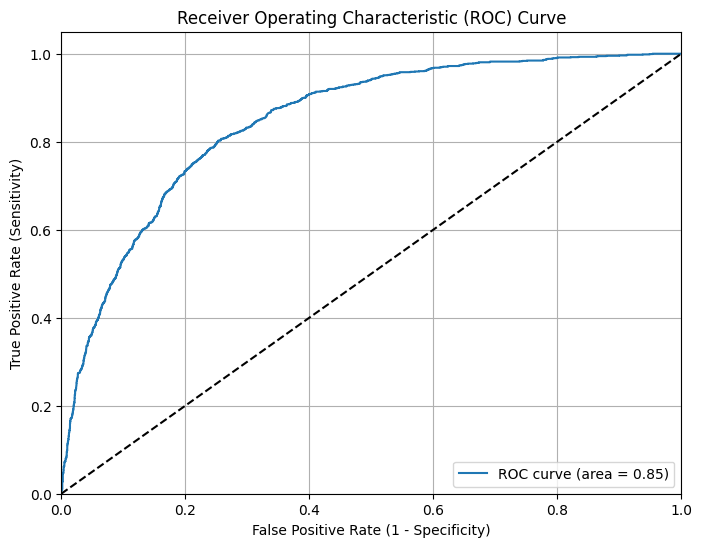

In [207]:
# Importing required library for ROC curve plotting
from sklearn import metrics
import matplotlib.pyplot as plt

def draw_roc(actual, probs):
    fpr, tpr, thresholds = metrics.roc_curve(actual, probs, drop_intermediate=False)
    auc_score = metrics.roc_auc_score(actual, probs)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % auc_score)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    return fpr, tpr, thresholds

# Drawing the ROC curve using predicted probabilities on the training set
fpr, tpr, thresholds = draw_roc(y_train_pred_final.Churn, y_train_pred_final.Churn_Prob)

# Running model at 0.3 or near it

In [220]:
y_train_pred_final['final_predicted'] = y_train_pred_final.Churn_Prob.map(lambda x: 1 if x > 0.36 else 0)
y_train_pred_final.head()

,Churn,Churn_Prob,CustID,final_predicted
0,0,0.114824,879,0
1,0,0.235517,5790,0
2,1,0.578150,6498,1
3,1,0.585423,880,1
4,1,0.699087,2784,1


In [211]:
from sklearn import metrics
confusion = metrics.confusion_matrix(y_train_pred_final.Churn, y_train_pred_final.final_predicted )
print(confusion)

[[2924  711]
 [ 354  933]]


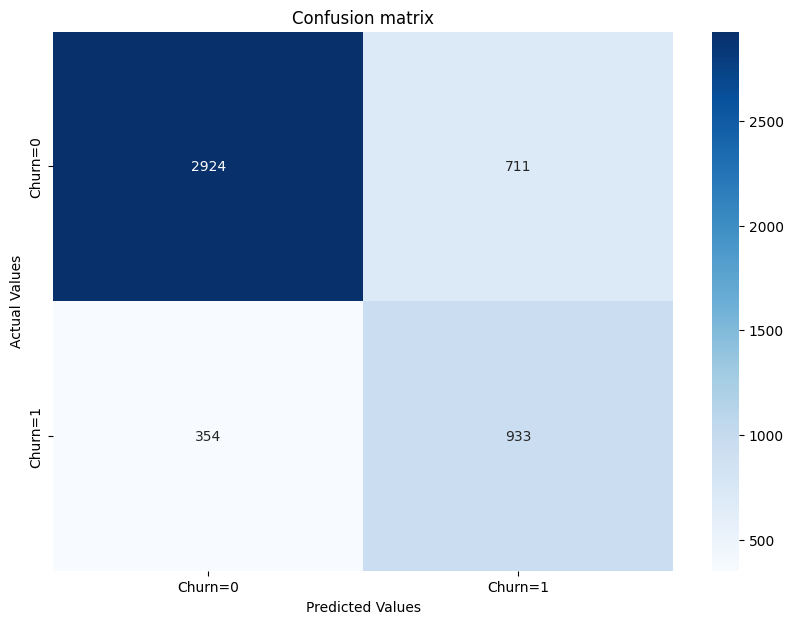

In [212]:
#visualizing the confusion metrics
plt.figure(figsize = (10,7))
sns.heatmap(confusion, annot=True, fmt='d', cmap="Blues", xticklabels=['Churn=0', 'Churn=1'], yticklabels=['Churn=0', 'Churn=1'])
plt.title("Confusion matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()
#0 = non churn
#1 = churn
#3956/(3263+693+594+372)

In [222]:
print(metrics.accuracy_score(y_train_pred_final.Churn, y_train_pred_final.final_predicted))

0.7836245428687525


In [221]:
print(metrics.classification_report(y_train_pred_final.Churn, y_train_pred_final.final_predicted ))

              precision    recall  f1-score   support

           0       0.89      0.80      0.85      3635
           1       0.57      0.72      0.64      1287

    accuracy                           0.78      4922
   macro avg       0.73      0.76      0.74      4922
weighted avg       0.81      0.78      0.79      4922



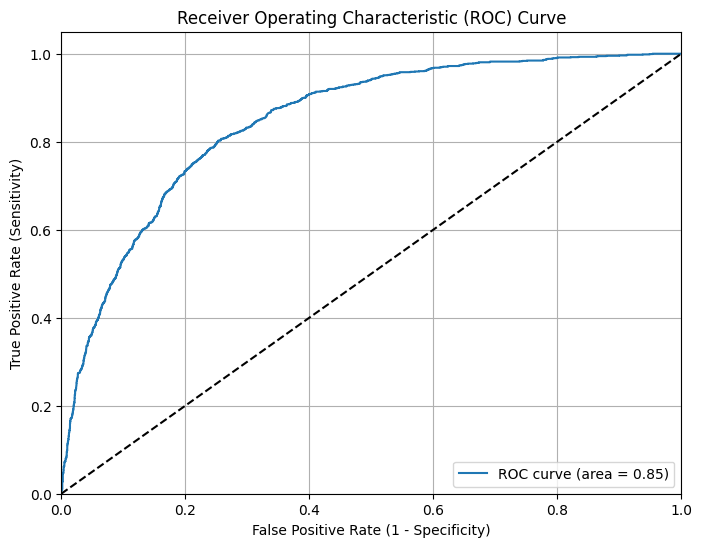

In [215]:
# Importing required library for ROC curve plotting
from sklearn import metrics
import matplotlib.pyplot as plt

def draw_roc(actual, probs):
    fpr, tpr, thresholds = metrics.roc_curve(actual, probs, drop_intermediate=False)
    auc_score = metrics.roc_auc_score(actual, probs)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % auc_score)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    return fpr, tpr, thresholds

# Drawing the ROC curve using predicted probabilities on the training set
fpr, tpr, thresholds = draw_roc(y_train_pred_final.Churn, y_train_pred_final.Churn_Prob)

In [216]:
# Let's calculate Accuracy, Sensitivity, and Specificity for various probability cutoffs
cutoff_df = pd.DataFrame(columns=['prob', 'accuracy', 'sensi', 'speci'])

# Probability thresholds from 0.0 to 0.9 with step 0.1
numbers = [float(x)/10 for x in range(10)]

for i in numbers:
    # Predict Churn based on current threshold
    y_pred = y_train_pred_final.Churn_Prob.map(lambda x: 1 if x > i else 0)
    cm = metrics.confusion_matrix(y_train_pred_final.Churn, y_pred)

    total = sum(sum(cm))
    accuracy = (cm[0,0] + cm[1,1]) / total
    speci = cm[0,0] / (cm[0,0] + cm[0,1])
    sensi = cm[1,1] / (cm[1,0] + cm[1,1])

    cutoff_df.loc[i] = [i, accuracy, sensi, speci]

display(cutoff_df)

,prob,accuracy,sensi,speci
0.0,0.0,0.261479,1.000000,0.000000
0.1,0.1,0.608492,0.944833,0.489409
0.2,0.2,0.712922,0.874903,0.655571
0.3,0.3,0.766558,0.783994,0.760385
0.4,0.4,0.792361,0.661228,0.838790
0.5,0.5,0.803738,0.538462,0.897662
0.6,0.6,0.798659,0.376845,0.948006
0.7,0.7,0.768590,0.154623,0.985970
0.8,0.8,0.741162,0.014763,0.998349
0.9,0.9,0.738521,0.000000,1.000000


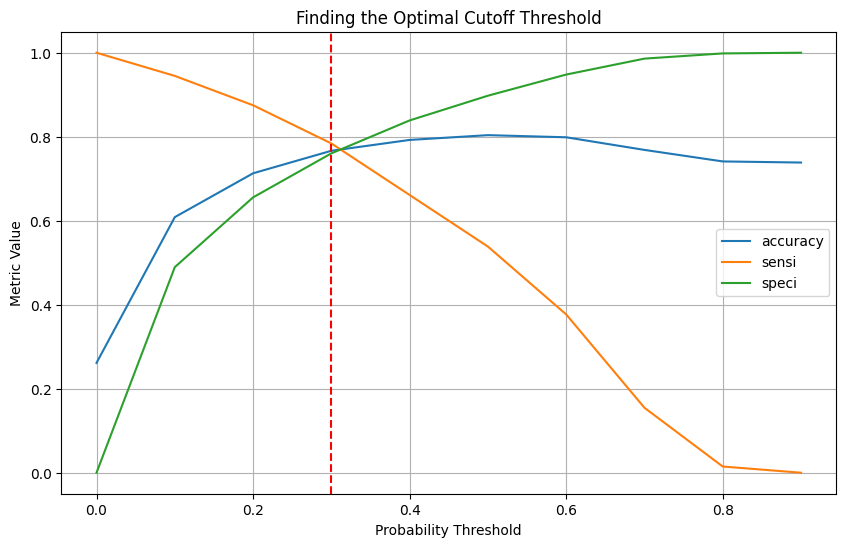

In [217]:
# Plotting Accuracy, Sensitivity, and Specificity to find the optimal cutoff point
cutoff_df.plot.line(x='prob', y=['accuracy', 'sensi', 'speci'], figsize=(10, 6))
plt.title('Finding the Optimal Cutoff Threshold')
plt.xlabel('Probability Threshold')
plt.ylabel('Metric Value')
plt.grid(True)
plt.axvline(x=0.3, color='r', linestyle='--', label='Approximate Intersection (~0.3)')
plt.show()